In [1]:
import pandas as pd

In [2]:
df=pd.read_csv("delivery_time.csv")
df.head()

,distance_km,delivery_time_min
0,7.5,34
1,4.6,25
2,8.3,33
3,6.9,31
4,1.6,15


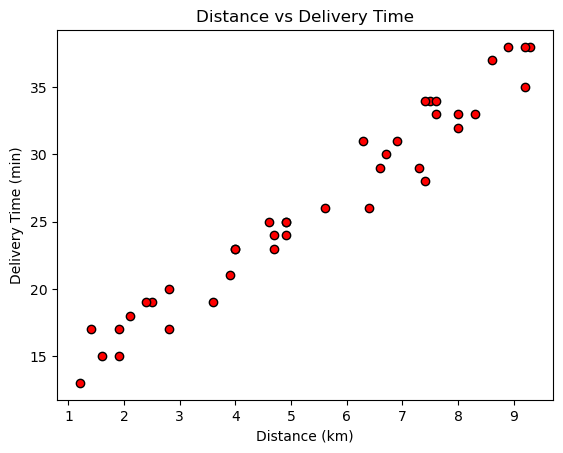

In [15]:
import matplotlib.pyplot as plt

plt.scatter(df['distance_km'], df['delivery_time_min'],color="red",edgecolor='k')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Time (min)')
plt.title('Distance vs Delivery Time')
plt.show()

In [4]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(df[['distance_km']], df.delivery_time_min)

LinearRegression()

In [7]:
prediction=model.predict(pd.DataFrame({"distance_km": [7]}))
print(prediction)

[30.67137739]


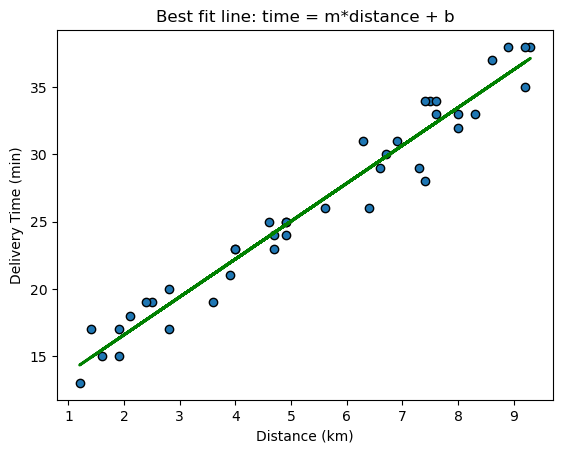

In [14]:
plt.scatter(df.distance_km,df.delivery_time_min,edgecolor='k')
plt.plot(df.distance_km,model.predict(df[['distance_km']]),color='green',linewidth="2")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (min)")
plt.title("Best fit line: time = m*distance + b")
plt.show()

In [17]:
df2=pd.read_csv('delivery_time_multi.csv')
df2.head()

,distance_km,traffic_level,raining,delivery_time_min
0,7.9,5,1,38
1,2.3,10,0,26
2,1.0,2,1,18
3,1.6,6,1,26
4,7.1,6,0,34


In [25]:
model2=LinearRegression()
features=['distance_km','traffic_level','raining']
model2.fit(df2[features],df2.delivery_time_min)

LinearRegression()

In [26]:
new_order = pd.DataFrame({'distance_km': [7], 'traffic_level': [8], 'raining': [1]})
predicted = model2.predict(new_order)
print(predicted)

[39.80716222]


In [28]:
X=df2[features]
y=df2.delivery_time_min

In [39]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [40]:
y_train.shape

(48,)

In [41]:
model3=LinearRegression()
model3.fit(X_train,y_train)

LinearRegression()

In [46]:
train_r2 = model3.score(X_train, y_train)
test_r2 = model3.score(X_test, y_test)

print(f"R^2 on training data (seen)    = {train_r2:.3f}")
print(f"R^2 on test data (never seen)  = {test_r2:.3f}")

R^2 on training data (seen)    = 0.959
R^2 on test data (never seen)  = 0.885
